In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from scipy.sparse import issparse

project_root = Path.cwd().resolve().parent
sys.path.insert(0, str(project_root))

from src.features.credit_features import (
    BASELINE_FEATURES,
    make_row_features,
    split_by_issue_month,
)

policy_file = (
    project_root
    / "models"
    / "checkpoints"
    / "pd_policy_2014_unweighted_isotonic.json"
)

if not policy_file.is_file():
    raise FileNotFoundError(
        f"Frozen Notebook 05 policy not found: {policy_file}"
    )

with policy_file.open("r", encoding="utf-8") as stream:
    policy = json.load(stream)

required_policy_fields = {
    "model_file",
    "preprocessor_file",
    "selection_period",
    "evaluation_period",
    "target_el_rate",
    "lgd_assumption",
    "pd_threshold",
}

missing_policy_fields = required_policy_fields - set(policy)
if missing_policy_fields:
    raise KeyError(
        f"Missing policy fields: {sorted(missing_policy_fields)}"
    )

if policy["selection_period"] != "2014":
    raise ValueError("Unexpected policy-selection period.")
if policy["evaluation_period"] != "2015":
    raise ValueError("Unexpected policy-evaluation period.")

optimal_threshold = float(policy["pd_threshold"])

if not 0 < optimal_threshold < 1:
    raise ValueError("Saved PD boundary must be between 0 and 1.")

print(f"Imports successful. SHAP version: {shap.__version__}")
print(f"Loaded frozen policy: {policy_file.name}")
print(f"Full-precision PD boundary: {optimal_threshold:.17g}")
print(f"Historical LGD assumption: {policy['lgd_assumption']:.4%}")

Imports successful. SHAP version: 0.50.0
Loaded frozen policy: pd_policy_2014_unweighted_isotonic.json
Full-precision PD boundary: 0.16961130742049471
Historical LGD assumption: 50.0541%


Load Data, Preprocessor, and Model

In [3]:
print("Loading the 2015 OOT cohort and frozen model artifacts...")

pd_file = (
    project_root
    / "data"
    / "processed"
    / "pd_cohort_2011_2015_36m.parquet"
)

data = pd.read_parquet(pd_file)
splits = split_by_issue_month(data)
test_ready = make_row_features(splits["test"])

checkpoints_dir = project_root / "models" / "checkpoints"

# These filenames come from the policy saved by Notebook 05.
preprocessor = joblib.load(
    checkpoints_dir / policy["preprocessor_file"]
)
calibrated_model = joblib.load(
    checkpoints_dir / policy["model_file"]
)

# SHAP explains the underlying raw LightGBM model, not the
# subsequent isotonic mapping.
raw_model_file = (
    checkpoints_dir / "lightgbm_challenger_unweighted.joblib"
)
lgb_model = joblib.load(raw_model_file)

assert list(preprocessor.feature_names_in_) == list(
    BASELINE_FEATURES
), "Notebook 03 preprocessor input features do not match."

feature_names = [
    str(name)
    for name in preprocessor.get_feature_names_out()
]

fitted_model_names = [
    str(name)
    for name in lgb_model.feature_name_
]

assert len(feature_names) == len(fitted_model_names)

# LightGBM stores spaces in feature names as underscores.
assert [
    name.replace(" ", "_")
    for name in feature_names
] == fitted_model_names, (
    "The transformed feature order does not match the raw LightGBM."
)

# Verify that the calibrated wrapper contains the same raw model schema.
calibrated_base_names = [
    str(name)
    for name in calibrated_model.estimator.estimator.feature_name_
]
assert calibrated_base_names == fitted_model_names

# Reproducible SHAP sample; the original row indices preserve
# correspondence between the transformed data and test_ready.
sample_raw = test_ready[BASELINE_FEATURES].sample(
    n=10_000,
    random_state=42,
)

X_sample = preprocessor.transform(sample_raw)

if issparse(X_sample):
    X_sample_named = pd.DataFrame.sparse.from_spmatrix(
        X_sample,
        index=sample_raw.index,
        columns=feature_names,
    )
else:
    X_sample_named = pd.DataFrame(
        X_sample,
        index=sample_raw.index,
        columns=feature_names,
    )

assert X_sample_named.index.equals(sample_raw.index)
assert X_sample_named.shape[1] == len(feature_names)

print(f"2015 OOT cohort: {len(test_ready):,} loans")
print(f"SHAP sample: {len(sample_raw):,} loans")
print(f"Transformed model features: {len(feature_names)}")
print(f"Raw model file: {raw_model_file.name}")
print(f"Calibrated model file: {policy['model_file']}")
print("Feature order and model schemas verified.")

Loading the 2015 OOT cohort and frozen model artifacts...
2015 OOT cohort: 283,026 loans
SHAP sample: 10,000 loans
Transformed model features: 98
Raw model file: lightgbm_challenger_unweighted.joblib
Calibrated model file: calibrated_lightgbm_unweighted_isotonic.joblib
Feature order and model schemas verified.


## Global model explanation

Tree SHAP describes the fitted **unweighted LightGBM** on a reproducible sample of 10,000 loans from the 2015 OOT cohort. With `model_output="raw"`, contributions are expressed on the base model's margin/log-odds scale, **not** as changes in the final isotonic-calibrated PD. The plot shows model associations, not causal effects or evidence of legal compliance.

The explanation and group-level audit apply to the historical model and simulated decisions for originated loans in the selected 2015 cohort. They do not establish how the model would behave for rejected applicants, verify that every predictor was available before an actual approval decision, or demonstrate regulatory compliance. In particular, `verification_status` timing remains an unverified operational assumption, and the target is recorded final-status charge-off rather than fixed-horizon default.

Calculating SHAP values for the raw unweighted LightGBM...


c:\Users\Yahya\anaconda3\envs\myenv\Lib\site-packages\shap\explainers\_tree.py:587: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


SHAP matrix shape: (10000, 98)
SHAP explanation scale: raw LightGBM margin/log-odds.


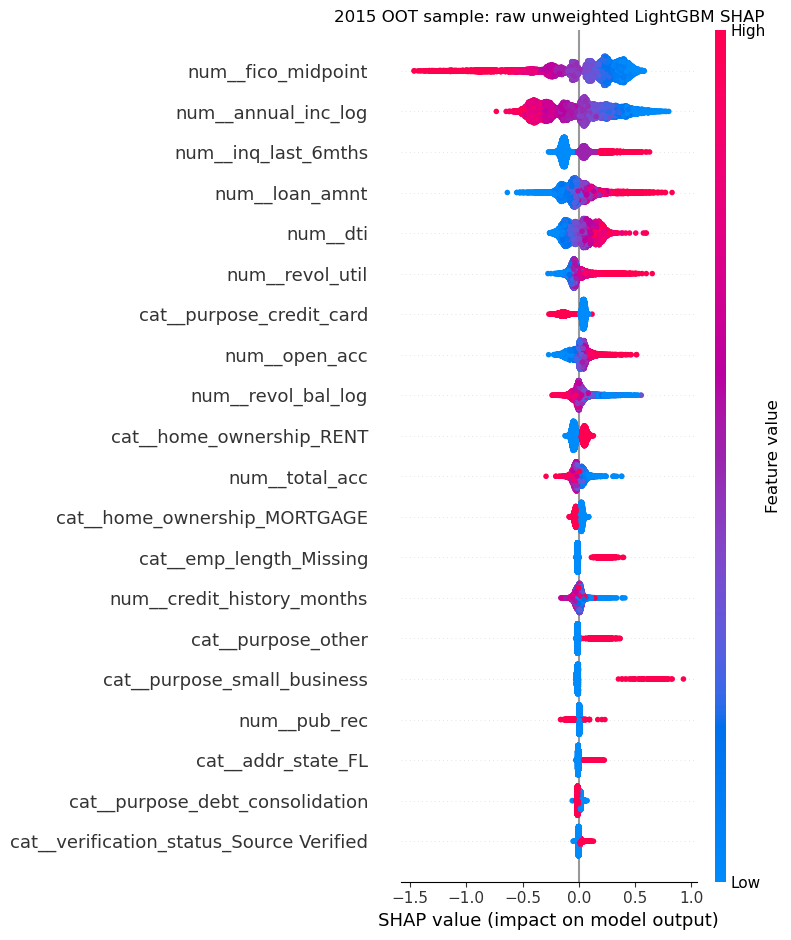

Saved global SHAP plot: shap_global_unweighted_lightgbm_2015.png


In [5]:
print("Calculating SHAP values for the raw unweighted LightGBM...")

# This is for interpreting the fitted tree model. SHAP's default raw
# output for binary LightGBM is on the model-margin/log-odds scale,
# not the calibrated probability scale.
explainer = shap.TreeExplainer(
    lgb_model,
    model_output="raw",
)

# Keep original sample row indices so local explanations can be matched
# back to the corresponding 2015 observations.
if issparse(X_sample):
    X_shap = pd.DataFrame(
        X_sample.toarray(),
        index=sample_raw.index,
        columns=feature_names,
    )
else:
    X_shap = X_sample_named.copy()

shap_result = explainer.shap_values(X_shap)

# Depending on the SHAP/LightGBM version, binary output can be a
# list [class 0, class 1] or a single (rows, features) array.
if isinstance(shap_result, list):
    if len(shap_result) != 2:
        raise ValueError("Unexpected number of SHAP class outputs.")
    shap_values_default = np.asarray(shap_result[1])
else:
    shap_values_default = np.asarray(shap_result)

if shap_values_default.shape != X_shap.shape:
    raise ValueError(
        "SHAP-value shape does not match the transformed sample."
    )

print(f"SHAP matrix shape: {shap_values_default.shape}")
print("SHAP explanation scale: raw LightGBM margin/log-odds.")

# Use a distinct filename so the old balanced-model figure is not reused.
figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

shap.summary_plot(
    shap_values_default,
    X_shap,
    feature_names=feature_names,
    max_display=20,
    show=False,
)

plt.title("2015 OOT sample: raw unweighted LightGBM SHAP")
plt.tight_layout()

global_plot_file = (
    figures_dir
    / "shap_global_unweighted_lightgbm_2015.png"
)

plt.savefig(
    global_plot_file,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(f"Saved global SHAP plot: {global_plot_file.name}")

Local Explainability (Simulating an Adverse Action Notice)

Creating a reproducible local model explanation...
Selected applicant ID: 38584295
Raw LightGBM probability: 50.37%
Calibrated PD: 54.55%
Frozen rejection threshold: 16.961131%


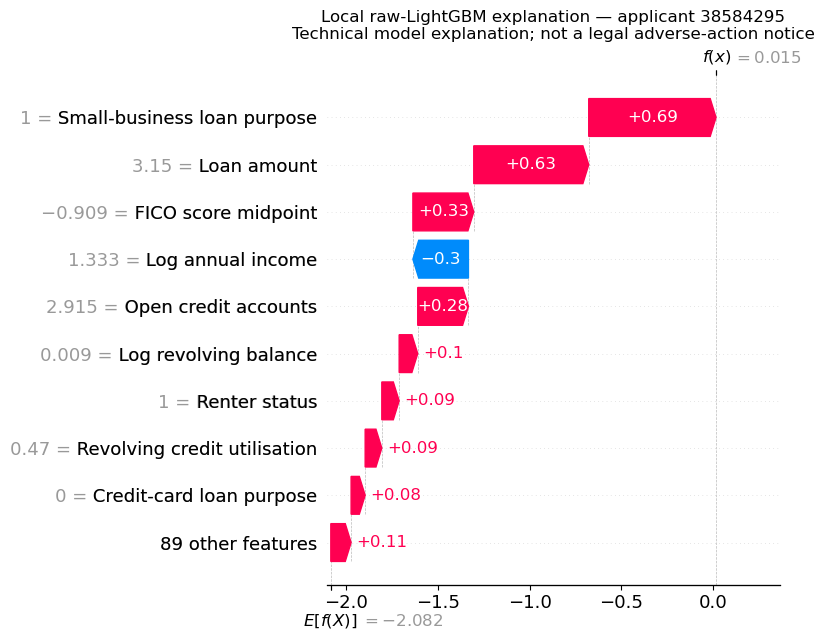

Saved local SHAP plot: shap_local_model_explanation_2015_readable.png


In [10]:
print("Creating a reproducible local model explanation...")

# Convert the sampled rows to a regular DataFrame for stable indexing.
sample_raw = test_ready.loc[
    sample_raw.index
].copy()

# Raw model probability and final calibrated PD for the same SHAP sample.
sample_raw["raw_PD"] = lgb_model.predict_proba(
    X_sample_named
)[:, 1]

sample_raw["calibrated_PD"] = calibrated_model.predict_proba(
    X_sample_named
)[:, 1]

sample_raw["Decision_Reject"] = (
    sample_raw["calibrated_PD"] > optimal_threshold
).astype("int8")

rejected_candidates = sample_raw.loc[
    sample_raw["Decision_Reject"].eq(1)
].sort_values(
    ["calibrated_PD", "id"],
    ascending=[False, True],
)

if rejected_candidates.empty:
    raise ValueError(
        "No rejected observations were found in the SHAP sample."
    )

selected_index = rejected_candidates.index[0]
selected_id = rejected_candidates.loc[selected_index, "id"]

# Position within the SHAP sample, not the full test DataFrame.
shap_position = list(X_shap.index).index(selected_index)

print(f"Selected applicant ID: {selected_id}")
print(
    "Raw LightGBM probability: "
    f"{sample_raw.loc[selected_index, 'raw_PD']:.2%}"
)
print(
    "Calibrated PD: "
    f"{sample_raw.loc[selected_index, 'calibrated_PD']:.2%}"
)
print(f"Frozen rejection threshold: {optimal_threshold:.6%}")

expected_value = explainer.expected_value
if isinstance(expected_value, (list, np.ndarray)):
    expected_value = expected_value[1]

def readable_feature_name(name):
    name = str(name)

    if name.startswith("num__"):
        name = name[len("num__"):]

    elif name.startswith("cat__"):
        name = name[len("cat__"):]

    replacements = {
        "fico_midpoint": "FICO score midpoint",
        "annual_inc_log": "Log annual income",
        "inq_last_6mths": "Recent credit inquiries",
        "loan_amnt": "Loan amount",
        "dti": "Debt-to-income ratio",
        "revol_util": "Revolving credit utilisation",
        "revol_bal_log": "Log revolving balance",
        "open_acc": "Open credit accounts",
        "total_acc": "Total credit accounts",
        "credit_history_months": "Credit history length",
        "pub_rec": "Public-record count",
        "emp_length": "Employment length",
        "home_ownership_RENT": "Renter status",
        "home_ownership_MORTGAGE": "Mortgage status",
        "purpose_small_business": "Small-business loan purpose",
        "purpose_credit_card": "Credit-card loan purpose",
        "purpose_debt_consolidation": "Debt-consolidation purpose",
        "purpose_other": "Other loan purpose",
        "addr_state_FL": "Florida address",
        "verification_status_Source Verified": (
            "Source-verified income"
        ),
    }

    return replacements.get(name, name.replace("_", " "))


readable_feature_names = [
    readable_feature_name(name)
    for name in feature_names
]

local_explanation = shap.Explanation(
    values=shap_values_default[shap_position],
    base_values=expected_value,
    data=X_shap.loc[selected_index],
    feature_names=readable_feature_names,
)

fig = plt.figure(figsize=(10, 6))
shap.waterfall_plot(
    local_explanation,
    show=False,
)

plt.title(
    f"Local raw-LightGBM explanation — applicant {selected_id}\n"
    "Technical model explanation; not a legal adverse-action notice"
)

plt.tight_layout()

figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

local_plot_file = (
    figures_dir
    / "shap_local_model_explanation_2015_readable.png"
)

plt.savefig(
    local_plot_file,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(f"Saved local SHAP plot: {local_plot_file.name}")

### Interpretation of the local explanation

The readable labels are presentation aliases for one-hot encoded and engineered model features. They do not change the underlying SHAP values or model input. The waterfall identifies features that contributed to the raw LightGBM output for this observation; it does not convert those contributions into calibrated-probability changes or legally sufficient adverse-action reasons.

A production adverse-action process would require separate reason-code validation, including reason specificity, stability, completeness, and compliance review.

Fairness Auditing - False Positive Rate (FPR) Parity

In [8]:
print("Conducting fairness audit using the frozen 2014 policy...")

# Transform the complete 2015 OOT cohort using the same preprocessor
# and named-feature interface used in Notebook 04 and Notebook 05.
X_test_full = preprocessor.transform(
    test_ready[BASELINE_FEATURES]
)

feature_names_full = [
    str(name)
    for name in preprocessor.get_feature_names_out()
]

if issparse(X_test_full):
    X_test_full_named = pd.DataFrame.sparse.from_spmatrix(
        X_test_full,
        index=test_ready.index,
        columns=feature_names_full,
    )
else:
    X_test_full_named = pd.DataFrame(
        X_test_full,
        index=test_ready.index,
        columns=feature_names_full,
    )

# Generate final calibrated PDs for the complete 2015 OOT cohort.
test_ready["PD_calibrated"] = calibrated_model.predict_proba(
    X_test_full_named
)[:, 1]

# Apply the frozen policy from Notebook 05.
test_ready["Decision_Reject"] = (
    test_ready["PD_calibrated"] > optimal_threshold
).astype("int8")

# Homeownership is used only as a socioeconomic proxy.
test_ready["is_renter"] = (
    test_ready["home_ownership"]
    .astype("string")
    .str.upper()
    .eq("RENT")
)

def group_metrics(frame):
    y = frame["charged_off"].astype("int8")
    reject = frame["Decision_Reject"].astype("int8")

    tn = int(((y == 0) & (reject == 0)).sum())
    fp = int(((y == 0) & (reject == 1)).sum())
    fn = int(((y == 1) & (reject == 0)).sum())
    tp = int(((y == 1) & (reject == 1)).sum())

    return pd.Series({
        "loans": len(frame),
        "charge_off_rate": y.mean(),
        "rejection_rate": reject.mean(),
        "fpr": fp / (fp + tn) if (fp + tn) else np.nan,
        "fnr": fn / (fn + tp) if (fn + tp) else np.nan,
        "tpr": tp / (tp + fn) if (tp + fn) else np.nan,
    })

test_ready["group"] = np.where(
    test_ready["is_renter"],
    "Renters",
    "Non-renters",
)

fairness_table = (
    test_ready
    .groupby("group", sort=True)
    .apply(group_metrics, include_groups=False)
)

display(fairness_table.round(4))

fpr_renters = fairness_table.loc["Renters", "fpr"]
fpr_non_renters = fairness_table.loc["Non-renters", "fpr"]

fpr_ratio = fpr_renters / fpr_non_renters

print(f"Frozen PD threshold: {optimal_threshold:.17g}")
print(f"FPR ratio, renters / non-renters: {fpr_ratio:.4f}")

Conducting fairness audit using the frozen 2014 policy...


,loans,charge_off_rate,rejection_rate,fpr,fnr,tpr
group,,,,,,
Non-renters,161563.0,0.1280,0.2288,0.2038,0.6011,0.3989
Renters,121463.0,0.1765,0.4200,0.3850,0.4169,0.5831


Frozen PD threshold: 0.16961130742049471
FPR ratio, renters / non-renters: 1.8895


confidence intervals

In [9]:
from statsmodels.stats.proportion import proportion_confint

def group_confusion_counts(frame):
    y = frame["charged_off"].astype("int8")
    reject = frame["Decision_Reject"].astype("int8")

    tn = int(((y == 0) & (reject == 0)).sum())
    fp = int(((y == 0) & (reject == 1)).sum())
    fn = int(((y == 1) & (reject == 0)).sum())
    tp = int(((y == 1) & (reject == 1)).sum())

    return tn, fp, fn, tp

fpr_intervals = {}

for group_name, group_frame in test_ready.groupby("group"):
    tn, fp, fn, tp = group_confusion_counts(group_frame)

    lower, upper = proportion_confint(
        count=fp,
        nobs=fp + tn,
        alpha=0.05,
        method="wilson",
    )

    fpr_intervals[group_name] = {
        "false_positives": fp,
        "true_negatives": tn,
        "fpr": fp / (fp + tn),
        "fpr_lower_95": lower,
        "fpr_upper_95": upper,
    }

fpr_interval_table = pd.DataFrame(fpr_intervals).T
display(fpr_interval_table.round(4))

,false_positives,true_negatives,fpr,fpr_lower_95,fpr_upper_95
Non-renters,28708.0,112167.0,0.2038,0.2017,0.2059
Renters,38512.0,61507.0,0.3850,0.3820,0.3881


## Conclusion: explainability and fairness

Tree SHAP was used to describe the raw output of the final unweighted LightGBM challenger on a reproducible sample of 10,000 loans from the 2015 OOT cohort. FICO midpoint, logged annual income, recent inquiries, loan amount, DTI, and revolving utilisation were among the main contributors to model output in this sample. These are model associations, not causal effects. The SHAP values are on the raw LightGBM margin/log-odds scale and do not represent percentage-point changes in the final isotonic-calibrated PD.

The local waterfall plot illustrates the model contributions for one reproducibly selected rejected 2015 observation. It is a technical model explanation, not a legally sufficient adverse-action notice. SHAP contributions should not be treated as automatically valid regulatory reason codes or as proof of ECOA compliance.

The fairness audit applied the frozen PD boundary of 0.16961130742049471 to the 2015 OOT cohort. Homeownership was used as a socioeconomic proxy, not as a complete representation of legally protected characteristics. Renters had a 42.00% rejection rate compared with 22.88% for non-renters. Their false-positive rate was 38.50%, compared with 20.38% for non-renters, giving an FPR ratio of 1.8895. Renters also had a higher observed charge-off rate, 17.65% versus 12.80%, so the FPR difference should be interpreted together with the underlying group risk and the other reported error rates.

The audit also showed a trade-off in error types. Renters had a higher true-positive rate and lower false-negative rate, but also a higher false-positive rate under the common threshold. The results identify a group-level allocation disparity under this frozen expected-loss policy; they do not independently establish unlawful discrimination. Confidence intervals, alternative thresholds, calibration-by-group, and additional fairness metrics would be needed for a broader fairness assessment.

Any fairness mitigation or threshold adjustment would define a new policy. It must be selected using development data and evaluated prospectively or on a separate holdout, without tuning to the final 2015 OOT outcomes.